# Phase 6: Final Release & Sealed Test Verification (`Base` vs `CoT SFT` vs `GRPO RL`)

Runs the **single-shot sealed Phase 6 release benchmark** across all release candidates cleanly on GPU (`CUDA` BF16) or CPU (`FP32`):

1. **Load & SHA-256 Verify Checkpoints:**
   - **Base (`23a72f3a...`, Step `26,047`)** — `SimpleStories` test retention anchor
   - **CoT SFT (`e57bf52b...`, Step `10,000`)** — Phase 4 winning reasoning checkpoint & GRPO parent
   - **GRPO RL `best` (`486683da...`, Step `100`)** — lowest held-out val error rate (`98.2%` monitor)
   - **GRPO RL `latest` (`486683da...`, Step `300`)** — final RL step (`1.0000` hard-train reward)
2. **Sealed Arithmetic Test Split (`test.jsonl`, all `6,002` rows, `allow_sealed_test=True`, `strict_trace=True`):**
   - Strict binary `{0, 1}` verification (`EOS`, `Work:` format, every clause `LHS == RHS`, `Work:` → `Answer:`, exact match), masked test loss, per-op & 35-category breakdown, and pairwise **`RL fixed` vs `RL broke`** trace audit.
3. **Unseen Wording Generalization (`test` canonicals, `strict_trace=True`)** across all 3 reasoning models.
4. **`SimpleStories` Held-Out `test` Split Retention Check** (`test_loss`, `test_ppl`, `test_bpb`, 4-choice `Story Cloze`, RoPE position scaling `1–1,024`) across Base, CoT SFT, and both RL models.
5. **Deterministic Hard-Probe Audit & Release Artifact Provenance Manifest.**

In [1]:
from pathlib import Path
import sys

root = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "main.py").is_file()), Path.cwd().parent)
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

import torch

from src.infra.eval_setup import configure_eval_device, setup_notebook_environment

project_root = setup_notebook_environment(root)
device, dtype = configure_eval_device("auto")  # Uses CUDA BF16 on GPU VM, FP32 on local CPU

Project root located at: /home/MiniReasoner
ACTIVE EXECUTION DEVICE: CUDA
GPU Hardware:       NVIDIA A30
Total VRAM:         23.60 GB
Compute Capability: 8.0
Inference Dtype:    torch.bfloat16


/home/MiniReasoner/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load Release Candidates & Inspect GRPO Training Trajectory


Top checkpoints by validation loss for 23a72f3aa8d6487ca401b92b22ae229c (53 total):

Rank  Step    Val Loss    Train Mean  Filename
-------------------------------------------------------------------------------------
#1    25000   1.1302      1.1327      step-25000_val-1.130212310741517_train-1.1326...
#2    26047   1.1303      1.1231      step-26047_val-1.1303457730208912_train-1.123...
#3    26000   1.1315      1.1296      step-26000_val-1.1315013859334513_train-1.129...
#4    25500   1.1326      1.1301      step-25500_val-1.1326035355413773_train-1.130...
#5    24500   1.1350      1.1354      step-24500_val-1.134966506729165_train-1.1354...

--> Selected (latest): Step 26,047 | Val Loss: 1.1303 | Train Mean: 1.1231
Download complete and verified via SHA-256 checksum.
Loading checkpoint weights from: /home/MiniReasoner/checkpoints/23a72f3aa8d6487ca401b92b22ae229c/latest_step_26047_095810fa.pt

MINIREASONER CHECKPOINT & ARCHITECTURE SUMMARY
Stage / Step:                pretrain (ste

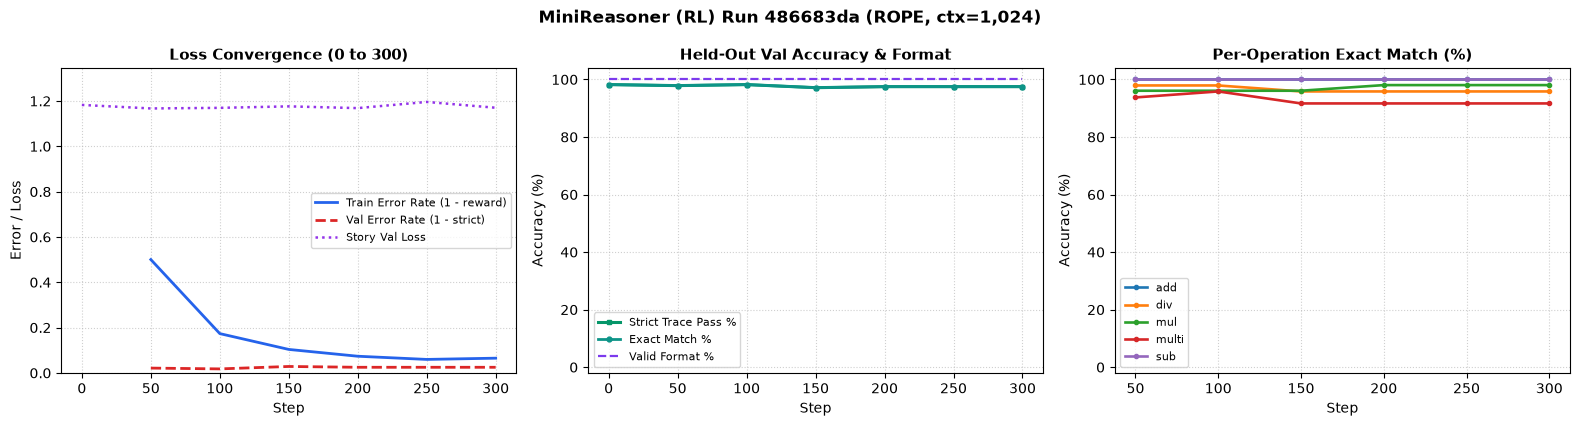

Initial Val Loss:        0.0179 (Step 0)
Latest Logged Val Loss:  0.0250 (Step 300)
Best Val Loss:           0.0179 (Step 0)
Peak Val Exact Match:    98.2% (Step 0)
Final Val Exact Match:   97.5% (Step 300)
Story Val Loss:          1.1826 (Step 0) -> 1.1702 (Step 300)


In [2]:
from src.infra.eval_setup import load_checkpoint_bundle, plot_run_history, select_run_and_checkpoint

CANDIDATE_SPECS = [
    {"key": "base", "label": "Base (Step 26,047)", "run_id": "23a72f3aa8d6487ca401b92b22ae229c", "alias": "latest", "arith": False},
    {"key": "sft", "label": "CoT SFT (Step 10,000)", "run_id": "e57bf52bb95842dba6628092261584c4", "alias": "latest", "arith": True},
    {"key": "rl_best", "label": "GRPO RL best (Step 100)", "run_id": "486683da19be4935911944b9663e6717", "alias": "best", "arith": True},
    {"key": "rl_latest", "label": "GRPO RL latest (Step 300)", "run_id": "486683da19be4935911944b9663e6717", "alias": "latest", "arith": True},
]

loaded_models = {}
for spec in CANDIDATE_SPECS:
    rid, ckpt_path, snap = select_run_and_checkpoint(run_id=spec["run_id"], checkpoint_alias=spec["alias"])
    bundle = load_checkpoint_bundle(ckpt_path, device, dtype, snapshot=snap, compare_with_base=False)
    loaded_models[spec["key"]] = {
        **spec,
        "run_id": rid,
        "checkpoint_path": ckpt_path,
        "snapshot": snap,
        "bundle": bundle,
    }

rl_latest_info = loaded_models["rl_latest"]
plot_run_history(
    rl_latest_info["bundle"]["metrics_history"],
    run_id=rl_latest_info["run_id"],
    model_config=rl_latest_info["bundle"]["model_config"],
    stage=rl_latest_info["bundle"]["stage"],
    snapshot=rl_latest_info["snapshot"],
)

## 2. Sealed Arithmetic Test Evaluation (`test.jsonl`, all `6,002` rows, `strict_trace=True`)

In [3]:
from src.core.benchmark import evaluate_arithmetic_split

EVAL_SPLIT = "test"
ALLOW_SEALED_TEST = True   # Phase 6 single-shot release evaluation on sealed test.jsonl
MAX_EXAMPLES = None        # Evaluate all 6,002 rows with zero sampling noise
BATCH_SIZE = 128 if device.type == "cuda" else 64

arith_results = {}
for spec in CANDIDATE_SPECS:
    if not spec["arith"]:
        continue
    entry = loaded_models[spec["key"]]
    b = entry["bundle"]
    print(f"\n>>> Evaluating {entry['label']} on sealed `{EVAL_SPLIT}` split...", flush=True)
    arith_results[entry["label"]] = evaluate_arithmetic_split(
        b["model"],
        b["tokenizer"],
        b["model_config"],
        b["arith_manifest"],
        device=device,
        dtype=dtype,
        eval_split=EVAL_SPLIT,
        allow_sealed_test=ALLOW_SEALED_TEST,
        max_examples=MAX_EXAMPLES,
        batch_size=BATCH_SIZE,
        use_kv_cache=True,
        max_misses_to_show=15,
        strict_trace=True,
    )


>>> Evaluating CoT SFT (Step 10,000) on sealed `test` split...
Restoring prepared SFT dataset from gdrive:MiniReasoner/data/sft/arith_v3_scratchpad_multistep_add-sub-mul-div_d3_signed_n12000_s42...
PHASE 6 SEALED TEST EVALUATION | split=test (6,002 rows) | format=scratchpad | multistep=True | kv_cache=True
Dataset:  /home/MiniReasoner/data/sft/arithmetic/arith_v3_scratchpad_multistep_add-sub-mul-div_d3_signed_n12000_s42
Hardware: CUDA | batch_size=128 | max_new_tokens=180
Computed masked test arith loss: 0.0020 (294,766 targets in 2.1s)
  Decoded 725/6,002 (12.1%) | 1.6s | 445.7 ex/s | ETA 11.8s
  Decoded 1,237/6,002 (20.6%) | 3.3s | 378.2 ex/s | ETA 12.6s
  Decoded 1,814/6,002 (30.2%) | 4.5s | 404.1 ex/s | ETA 10.4s
  Decoded 2,454/6,002 (40.9%) | 6.6s | 371.4 ex/s | ETA 9.6s
  Decoded 3,103/6,002 (51.7%) | 8.4s | 367.5 ex/s | ETA 7.9s
  Decoded 3,705/6,002 (61.7%) | 10.6s | 351.1 ex/s | ETA 6.5s
  Decoded 4,325/6,002 (72.1%) | 12.5s | 345.2 ex/s | ETA 4.9s
  Decoded 4,802/6,002 (80.

## 3. Side-by-Side Comparison & Paired `RL Fixed` / `RL Broke` Audit (`6,002` Sealed Test Rows)

In [4]:
from src.core.benchmark import compare_arithmetic_results

sft_label = loaded_models["sft"]["label"]
rl_best_label = loaded_models["rl_best"]["label"]
rl_latest_label = loaded_models["rl_latest"]["label"]

arith_comparison = compare_arithmetic_results(
    arith_results,
    baseline_name=sft_label,
    max_examples_to_show=8,
)

_ = compare_arithmetic_results(
    {rl_best_label: arith_results[rl_best_label], rl_latest_label: arith_results[rl_latest_label]},
    baseline_name=rl_best_label,
    max_examples_to_show=6,
)

PHASE 6 ARITHMETIC MODEL COMPARISON SUMMARY
Model                     Strict %  Exact %   Format %  Work %    Loss    add     div     mul     multi   sub     
------------------------------------------------------------------------------------------------------
CoT SFT (Step 10,000)     97.35     97.42     100.00    98.33     0.0020  99.75   96.92   95.50   95.00   99.58   
GRPO RL best (Step 100)   97.15     97.23     100.00    98.08     0.0024  99.75   96.50   95.33   94.25   99.92   
GRPO RL latest (Step 300) 96.93     97.03     100.00    97.88     0.0025  99.75   96.25   94.67   94.17   99.83   

------------------------------------------------------------------------------------------------------
PAIRED OUTCOMES VS BASELINE: CoT SFT (Step 10,000) (6,002 rows | strict_trace=True)
------------------------------------------------------------------------------------------------------

GRPO RL best (Step 100): both_pass=5,775 | fixed=56 | broke=68 | both_fail=103 | net=-12
  Per-Op Net

## 4. Unseen Wording Generalization on Sealed `test` Canonicals (`strict_trace=True`)

In [5]:
from src.core.benchmark import evaluate_wording_generalization

sealed_test_examples = arith_results[sft_label]["examples"]
wording_by_model = {}
for spec in CANDIDATE_SPECS:
    if not spec["arith"]:
        continue
    entry = loaded_models[spec["key"]]
    b = entry["bundle"]
    print(f"\n>>> Wording generalization: {entry['label']}")
    wording_by_model[entry["label"]] = evaluate_wording_generalization(
        b["model"],
        b["tokenizer"],
        sealed_test_examples,
        device=device,
        answer_format="scratchpad",
        n_problems=20,
        max_new_tokens=192,
        use_kv_cache=True,
        strict_trace=True,
    )


>>> Wording generalization: CoT SFT (Step 10,000)
WORDING GENERALIZATION (20 held-out problems, format=scratchpad, strict_trace=True)
  calculate               20/20  (100.0%)
  canonical               20/20  (100.0%)
  conversational_math     20/20  (100.0%)
  conversational_result   20/20  (100.0%)
  equation                20/20  (100.0%)
  word_numbers            20/20  (100.0%)
  word_op                 20/20  (100.0%)

>>> Wording generalization: GRPO RL best (Step 100)
WORDING GENERALIZATION (20 held-out problems, format=scratchpad, strict_trace=True)
  calculate               20/20  (100.0%)
  canonical               20/20  (100.0%)
  conversational_math     20/20  (100.0%)
  conversational_result   20/20  (100.0%)
  equation                20/20  (100.0%)
  word_numbers            19/20  ( 95.0%)
  word_op                 20/20  (100.0%)

>>> Wording generalization: GRPO RL latest (Step 300)
WORDING GENERALIZATION (20 held-out problems, format=scratchpad, strict_trace=True)
 

## 5. Held-Out `SimpleStories` `test` Split Retention Check (Zero Catastrophic Forgetting)


>>> SimpleStories held-out test check: Base (Step 26,047)
HELD-OUT TEST EVALUATION | SimpleStories/SimpleStories (test split)
Stories Scored:          250
Predicted Tokens:        101,970 (308,886 UTF-8 bytes | 3.03 bytes/tok)
Test Cross-Entropy Loss: 1.1393
Test Perplexity (PPL):   3.12
Test Bits-Per-Byte(BPB): 0.5426
----------------------------------------------------------------------
RoPE Context-Length Position Scaling:
  Tokens 1-256      | count=59,696  | Loss=1.1605 | PPL=3.19
  Tokens 257-512    | count=31,052  | Loss=1.1061 | PPL=3.02
  Tokens 513-1024   | count=11,222  | Loss=1.1184 | PPL=3.06

4-Choice Story Cloze Accuracy: 86/100 (86.0%) [Random baseline: 25.0%]

STORY COMPLETION SANITY CHECK (Greedy on CUDA)
[1] (209.6 tok/s) Once upon a time, there was a little girl named Mia who loved to explore. One day, she found a shiny rock in her backyard. It sparkled like stars in the night sky. Mia picked it up and felt a warm glow in her hand. She thought it was magic! 

Mia d

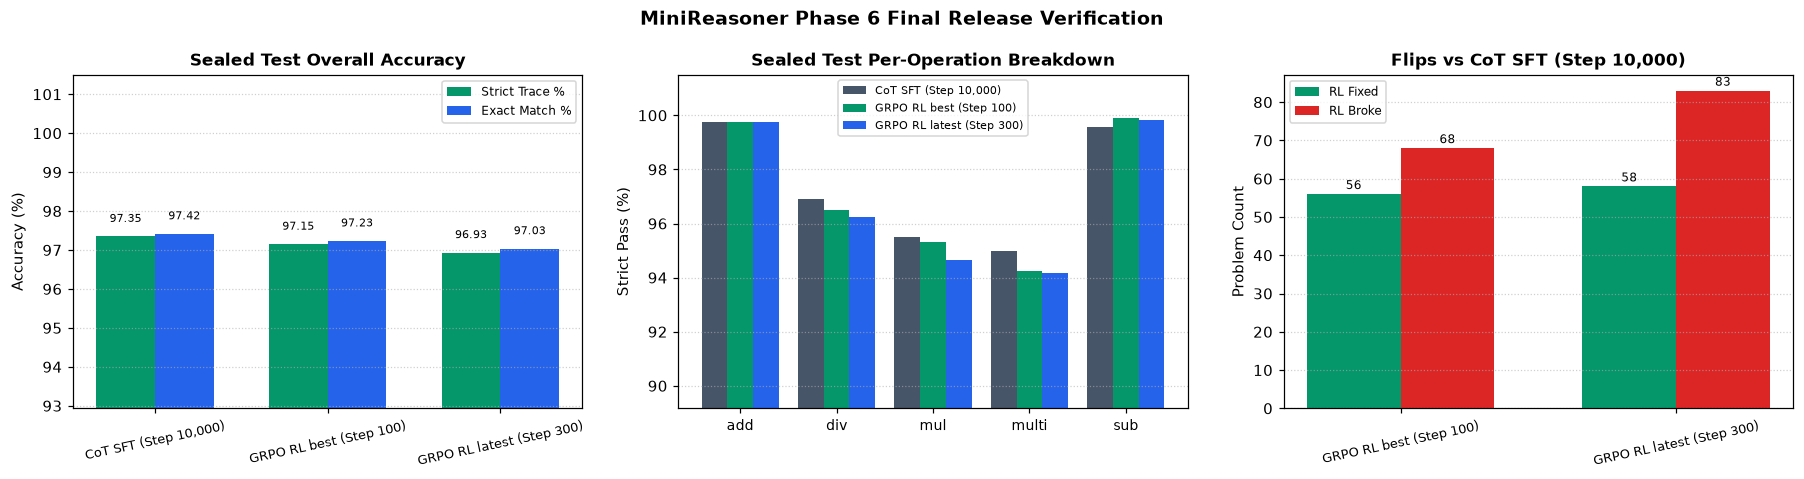

In [6]:
from src.core.benchmark import (
    compare_simplestories_results,
    evaluate_simplestories_test,
    fetch_simplestories_test_stories,
    plot_phase6_release_comparison,
)

n_stories = 250 if device.type == "cuda" else 64
n_cloze = 100 if device.type == "cuda" else 40
shared_test_stories, story_fetch_err = fetch_simplestories_test_stories(n_stories, n_cloze)
if story_fetch_err:
    print(f"Warning: could not fetch SimpleStories test split ({story_fetch_err}).")

story_results = {}
for spec in CANDIDATE_SPECS:
    entry = loaded_models[spec["key"]]
    b = entry["bundle"]
    print(f"\n>>> SimpleStories held-out test check: {entry['label']}")
    story_results[entry["label"]] = evaluate_simplestories_test(
        b["model"],
        b["tokenizer"],
        b["model_config"],
        device,
        n_stories=n_stories,
        n_cloze=n_cloze,
        test_stories=shared_test_stories if shared_test_stories else None,
    )

compare_simplestories_results(story_results)
plot_phase6_release_comparison(arith_comparison, story_results)

## 6. Deterministic Hard-Probe Stress Check & Final Release Provenance

In [7]:
from src.core.benchmark import create_ask_helper, load_eval_arithmetic_dataset
from src.infra.eval_setup import summarize_release_provenance

hard_probes = [
    ("What is 177 * 515?", 91155),
    ("What is -893 / (-19)?", 47),
    ("What is -875 / (-25)?", 35),
    ("What is -765 / 15?", -51),
    ("What is -95 * 672?", -63840),
    ("Compute 15 * 4 and 92 - 17, then subtract the second result from the first.", -15),
]

for spec in CANDIDATE_SPECS:
    if not spec["arith"]:
        continue
    entry = loaded_models[spec["key"]]
    b = entry["bundle"]
    ask = create_ask_helper(b["model"], b["tokenizer"], device=device, answer_format="scratchpad", use_cache=True)
    print(f"\n=== Stress Probes: {entry['label']} ===")
    for q, gold in hard_probes:
        ask(q, expected=gold)
    _ = ask("Once upon a time, there was a little", temperature=0.0, max_new_tokens=60)

winner_label = max(
    arith_results,
    key=lambda lbl: (
        round(arith_results[lbl]["strict_pass"], 6),
        round(arith_results[lbl]["exact_match"], 6),
        -round(arith_results[lbl]["eval_loss"], 6),
    ),
)
w_stats = arith_results[winner_label]
w_story = story_results.get(winner_label, {})
print("=" * 88)
print(f"PHASE 6 RELEASE WINNER: {winner_label}")
print(
    f"  Sealed Test Strict Pass: {w_stats['strict_pass'] * 100:.2f}% | "
    f"Exact Match: {w_stats['exact_match'] * 100:.2f}% | "
    f"Masked Loss: {w_stats['eval_loss']:.4f}"
)
if w_story and not w_story.get("skipped"):
    cloze_str = f"{w_story['story_mc_acc']:.1f}%" if w_story.get("story_mc_acc") is not None else "N/A"
    print(
        f"  SimpleStories Retention: Test CE={w_story['test_ce']:.4f} | "
        f"PPL={w_story['test_ppl']:.2f} | Cloze={cloze_str}"
    )
print("=" * 88)

arith_dir, _, loaded_arith_manifest = load_eval_arithmetic_dataset(loaded_models["sft"]["bundle"]["arith_manifest"])
_ = summarize_release_provenance(
    [loaded_models[spec["key"]] for spec in CANDIDATE_SPECS],
    arith_dir=arith_dir,
    arith_manifest=loaded_arith_manifest,
)


=== Stress Probes: CoT SFT (Step 10,000) ===
Q: What is 177 * 515? [MISS | expected 91155]
   Work: 515*100=51500; 515*70=35050; 515*7=3505; 51500+35050=86550; 86550+3505=90055
   Answer: 90055
   -> Extracted: 90055 (94 tok | 455ms | 206.5 tok/s)
------------------------------------------------------------------------------
Q: What is -893 / (-19)? [MISS | expected 47]
   Work: 19*40=760; 893-760=33; 19*1=33; 40+1=41
   Answer: 41
   -> Extracted: 41 (54 tok | 263ms | 205.1 tok/s)
------------------------------------------------------------------------------
Q: What is -875 / (-25)? [MISS | expected 35]
   Work: 25*30=750; 875-750=225; 25*9=225; 30+9=39
   Answer: 39
   -> Extracted: 39 (56 tok | 272ms | 205.7 tok/s)
------------------------------------------------------------------------------
Q: What is -765 / 15? [MISS | expected -51]
   Work: 15*40=600; 765-600=165; 15*9=165; 40+9=49; neg=-49
   Answer: -49
   -> Extracted: -49 (64 tok | 311ms | 206.0 tok/s)
---------------------